# EDA - Instagram Account Followers

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.0f}".format

In [2]:
# import Instagram dataset
data_raw = pd.read_csv("latest.csv")
data = data_raw.copy()

## Provenance & scope

### 1. Where did this data come from — who collected it, how, and why?

The data comes from the [Instagram Top Accounts GitHub repository](https://github.com/FastSocialCo/instagram-top-accounts). Specifically, we'll be using the `data/latest.csv` file captured on Nov 3, 2026. 

This dataset is collected by FastSocial and serves the ["Most Followed Instagram Accounts" page](https://fastsocial.co/most-followed-instagram-accounts?ref=github-dataset) that tracks and ranks top Instagram accounts. The data is collected from public Instagram accounts (private accounts are excluded) and their public follower counts from Instagram itself. Social accounts data is collected and tracked for various reasons, such as marketing and trend analysis.

### 2. What does one row represent?
Each row is one account with its basic information like the account unique username, the person or organization name, their follower count, account category like "Sports" or "Music", country, and rank (1 for top account and so on). 

### 3. How big is it, and what time period / geography / population does it cover?
This snapshot covers about 12,000 top public Instagram accounts and was captured on Nov 3, 2026. 

The data cover global Instagram user population and their interests on famous people/brands/organizations, indicating different topics of interest on Instagram.

The account data is from Instagram only and does not include follower count from other social media platforms. For example, Cristiano Ronaldo may have a Facebook account and more followers there that is not counted here. In addition, not everyone in the world use Instagram, and not every Instagram user explicitly express their interest by following celebrity accounts. For example, politics is a commonly followed topic, but not all politicians have an Instagram account and not all users follow them. Therefore, the data does not capture all possible public figures, categories, or the global level of interest of everyone in the world, just the Instagram global users population. 

### 4. What could this data plausibly generalize to — and what tempting question can it *not* answer?
The data can be used to measure and generalize the level of interest and attention of Instagram user population on different topics like music or sports. 

The data cannot measure and compare the level of interest and attention on different topics across the world because it only covers Instagram users and top Instagram account categories.

In addition, Instagram has roughly 3 billion users, showing positive and negative sentiment. Having a high follower count does not necessarily mean positive or negative influence in that category, so the data cannot be used to measure good or bad influence, just the magnitude of it.

## Structure & quality

### 5. What are the important variables, and what type is each (categorical, continuous, datetime, text, ID)? 

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12008 entries, 0 to 12007
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   date       12008 non-null  object
 1   username   12008 non-null  object
 2   followers  12008 non-null  int64 
 3   name       12008 non-null  object
 4   category   12008 non-null  object
 5   country    11572 non-null  object
 6   type       12008 non-null  object
 7   rank       12008 non-null  int64 
 8   also_in    37 non-null     object
 9   countries  11572 non-null  object
dtypes: int64(2), object(8)
memory usage: 938.3+ KB


The important variables and their types are:

| Variable | Description | Type |
|---|---|---|
| `username` | Instagram account unique username | string |
| `name` | person or organization name | string |
| `followers` | number of followers | int |
| `category` | account category (Sports, Music, Film & TV, etc.) | string |
| `also_in` | other categories the account belongs to | string |
| `rank` | rank number by followers (starting at 1) | int  |
| `country` | person/organization country code (US, CA, etc.) | string |


### 6. What's missing — and if nothing, how do you know? Completeness is a claim that must be earned: "no missing values (verified)" is real communication work. If something *is* missing, does it have a pattern?

In [4]:
data.isna().sum()

date             0
username         0
followers        0
name             0
category         0
country        436
type             0
rank             0
also_in      11971
countries      436
dtype: int64

In [5]:
data[data['country'].isna()].head(10)

,date,username,followers,name,category,country,type,rank,also_in,countries
34,2026-11-03,championsleague,120915997,UEFA Champions League,Sports,NaN,org,35,NaN,NaN
81,2026-11-03,fifaworldcup,67063969,FIFA World Cup,Sports,NaN,org,82,NaN,NaN
175,2026-11-03,f1,44716047,FORMULA 1,Sports,NaN,org,176,NaN,NaN
249,2026-11-03,adidasoriginals,33646592,adidas Originals,Fashion & beauty,NaN,org,250,NaN,NaN
265,2026-11-03,icc,32417285,ICC,Sports,NaN,org,266,NaN,NaN
295,2026-11-03,ronaldo,29189328,Ronaldo,Other,NaN,person,296,NaN,NaN
348,2026-11-03,nikolasferreiradm,26104798,Nikolas Ferreira,Public figures,NaN,person,349,NaN,NaN
377,2026-11-03,maccosmetics,24368280,M·A·C Cosmetics,Brands & Companies,NaN,org,378,NaN,NaN
384,2026-11-03,gadiiing,24023327,Gading Marten,Other,NaN,person,385,NaN,NaN
397,2026-11-03,thedeverakonda,23178765,Vijay Deverakonda,Other,NaN,person,398,NaN,NaN


There are 436 rows with missing `country` and `countries` values. The output above shows some examples. Some of these rows are either big global accounts like FIFA World Cup and FORMULA 1 or large global brands like adidas Originals and M·A·C Cosmetics. It makes sense that the country is not specified in these cases. We can leave them as is because we're not planning to analyze account influence and public interest by country.

In [6]:
data[data['also_in'].notnull()].head()

,date,username,followers,name,category,country,type,rank,also_in,countries
3,2026-11-03,selenagomez,402341384,Selena Gomez,Music,US,person,4,Film & TV,US
4,2026-11-03,kyliejenner,381243770,Kylie,Fashion & beauty,US,person,5,Film & TV,US
5,2026-11-03,therock,380259446,Dwayne Johnson,Film & TV,US,person,6,Sports,US;CA
6,2026-11-03,arianagrande,362177408,Ariana Grande,Music,US,person,7,Film & TV,US
7,2026-11-03,kimkardashian,343715350,Kim Kardashian,Film & TV,US,person,8,Fashion & beauty,US


The `also_in` column shows other categories an account belongs to and has 11971 missing values. Most accounts only belong to one category, and 37 accounts belong to multiple categories. The output above shows some examples of accounts that belong to multiple categories. These are top accounts with hundreds of millions of followers, so it's important to handle their account category and followers count properly when analyzing the data. 

One option is to analyze the main `category` and ignore `also_in`, but we would underestimate follower counts and reach for the secondary categories. Another option is to explode each account with multiple categories into separate rows, so an account follower count is counted in more than one category. It's not perfect because the follower count on a multi-category account does not mean the same level of public interest in each category.

### 7. Are there duplicates, impossible values, or suspicious encodings (999s, "unknown", mixed units)?

In [7]:
print(f"Duplicate rows: {data.duplicated().sum()}")
print(f"Duplicate usernames: {data['username'].duplicated().sum()}")
print(f"Duplicate names: {data['name'].duplicated().sum()}")

Duplicate rows: 0
Duplicate usernames: 0
Duplicate names: 17


In [8]:
(data[data.duplicated(subset="name", keep=False)]
 .sort_values(["name", "followers"], ascending=False)
 .head(10)
)

,date,username,followers,name,category,country,type,rank,also_in,countries
5360,2026-10-02,wonderwomanfilm,758675,Wonder Woman,Film & TV,US,org,5361,NaN,US
6982,2026-10-01,wonderwoman,359314,Wonder Woman,Film & TV,US,org,6983,NaN,US
6843,2026-10-02,tombraider,382012,Tomb Raider,Brands & Companies,GB,org,6844,NaN,GB
10498,2026-10-02,tombraidermovie,35000,Tomb Raider,Film & TV,GB,org,10499,NaN,GB
4382,2026-10-02,sonicthehedgehog,1272944,Sonic the Hedgehog,Brands & Companies,JP,org,4383,NaN,JP
6261,2026-10-02,sonicmovie,497681,Sonic the Hedgehog,Film & TV,US,org,6262,NaN,US
21,2026-11-03,realmadrid,182373924,Real Madrid C.F.,Sports,ES,org,22,NaN,ES
1208,2026-10-30,realmadridfem,9397756,Real Madrid C.F.,Sports,ES,org,1209,NaN,ES
163,2026-11-03,realdonaldtrump,46351033,President Donald J. Trump,Public figures,US,person,164,NaN,US
533,2026-11-01,potus,18896212,President Donald J. Trump,Public figures,US,org,534,NaN,US


Although all usernames are unique, there are 17 names that have duplicates in the dataset. Some of these are different people/organizations/brands who just happen to have the same name, while few others are another account made for the same person or similar topic, such as "wonderwoman" and "wonderwomanfilm" are both valid accounts for the "Wonder Woman" character. 

A duplicate account name about the same entity also represents extra public attention for that person/brand/organization, so it is worth keeping them and account for their impact. For the analysis, we will calculate and compare the average followers by categories. Therefore, the duplicate accounts about the same entity will have their follower counts combined and averaged out, which also helps balance out the influence of that entity a little bit.

In [9]:
data['category'].value_counts()

category
Sports                3612
Film & TV             2573
Music                 2422
Public figures        1419
Brands & Companies     832
Media                  435
Other                  412
Creators               167
Fashion & beauty       136
Name: count, dtype: int64

In [10]:
data.describe()

,followers,rank
count,"12,008","12,008"
mean,"4,275,701","6,004"
std,"18,107,682","3,467"
min,0,1
25%,"110,822","3,003"
50%,"550,530","6,004"
75%,"2,760,533","9,006"
max,"686,356,334","12,008"


In [11]:
data_raw[data_raw["followers"] == 0].shape

(7, 10)

The `category` column has valid values like 'Sports', 'Film & TV', and 'Music'. The `rank` column has min = 1 and max = 12,008, which are valid values. 

The `followers` column has min = 0, max = 686,356,334, and mean = 4,275,701, and these are all valid values. However, accounts with 0 followers don't represent any public interest and can skew the distribution. Since there are only 7 of them, we will drop these to focus on positive followers accounts.

In [12]:
# Keep only positive followers
data = data[data["followers"] > 0]

# Check if any zero followers remain
data[data["followers"] == 0]

,date,username,followers,name,category,country,type,rank,also_in,countries


### 8. What variables did the author create or transform, and why?

In [13]:
data['also_in'].value_counts()

also_in
Film & TV                 18
Music                     12
Sports                     3
Fashion & beauty           3
Sports; Public figures     1
Name: count, dtype: int64

In [14]:
# Create rows for accounts with additional categories
extra_categories = data[data["also_in"].notna()].copy()

# Split on semicolons and create one row per additional category
extra_categories["category"] = extra_categories["also_in"].str.split(";")
extra_categories = extra_categories.explode("category")
extra_categories["category"] = extra_categories["category"].str.strip()

exploded_data = (
    pd.concat([data, extra_categories], ignore_index=True)
    .sort_values("followers", ascending=False)
)

exploded_data.head(10)

,date,username,followers,name,category,country,type,rank,also_in,countries
0,2026-11-03,instagram,686356334,Instagram,Brands & Companies,US,org,1,NaN,US
1,2026-11-03,cristiano,679856205,Cristiano Ronaldo,Sports,PT,person,2,NaN,PT
2,2026-11-03,leomessi,517590373,Leo Messi,Sports,AR,person,3,NaN,AR;ES
12001,2026-11-03,selenagomez,402341384,Selena Gomez,Film & TV,US,person,4,Film & TV,US
3,2026-11-03,selenagomez,402341384,Selena Gomez,Music,US,person,4,Film & TV,US
12002,2026-11-03,kyliejenner,381243770,Kylie,Film & TV,US,person,5,Film & TV,US
4,2026-11-03,kyliejenner,381243770,Kylie,Fashion & beauty,US,person,5,Film & TV,US
12003,2026-11-03,therock,380259446,Dwayne Johnson,Sports,US,person,6,Sports,US;CA
5,2026-11-03,therock,380259446,Dwayne Johnson,Film & TV,US,person,6,Sports,US;CA
6,2026-11-03,arianagrande,362177408,Ariana Grande,Music,US,person,7,Film & TV,US


We transformed the `also_in` values into separate rows for each additional category. For example, we can see that Selena Gomez now has 2 rows, one for Film & TV and one for Music, each with the same follower count.

Each account keeps its original `category` row, and its `followers` count is repeated in each additional category row. This lets us analyze followers by category, but category totals should not be added together because some accounts appear more than once.

## Distributions & relationships

### 9. What does each key variable look like — shape, center, spread, outliers 

*Do this with plots, but then also with words; do the work of interpretation for your audience.*

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12001 entries, 0 to 12000
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   date       12001 non-null  object
 1   username   12001 non-null  object
 2   followers  12001 non-null  int64 
 3   name       12001 non-null  object
 4   category   12001 non-null  object
 5   country    11565 non-null  object
 6   type       12001 non-null  object
 7   rank       12001 non-null  int64 
 8   also_in    37 non-null     object
 9   countries  11565 non-null  object
dtypes: int64(2), object(8)
memory usage: 1.0+ MB


#### Followers distribution

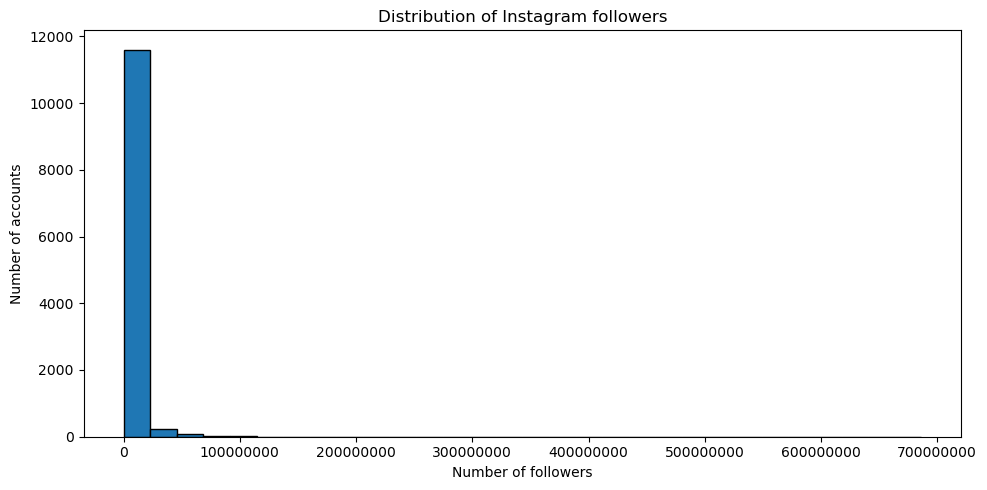

In [16]:
plt.figure(figsize=(10, 5))
plt.hist(data['followers'], bins=30, edgecolor="black")
plt.title("Distribution of Instagram followers")
plt.xlabel("Number of followers")
plt.ylabel("Number of accounts")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

In [17]:
# create column for log followers
data['log_followers'] = np.log10(data['followers'])
exploded_data['log_followers'] = np.log10(data['followers'])

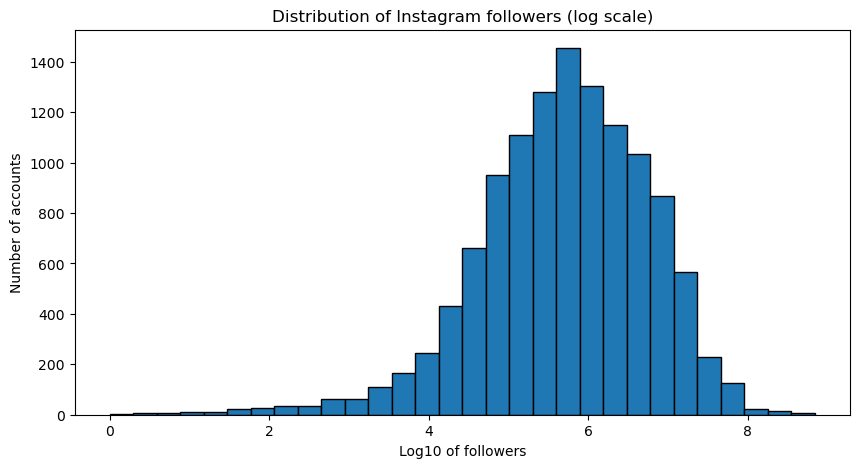

In [18]:
plt.figure(figsize=(10, 5))
plt.hist(data['log_followers'], bins=30, edgecolor="black")
plt.title("Distribution of Instagram followers (log scale)")
plt.xlabel("Log10 of followers")
plt.ylabel("Number of accounts")
plt.show()

The original `followers` count distribution is strongly right-skewed: most accounts have relatively fewer followers, while a small number have exceptionally large follower counts.

The log-scale histogram makes the spread easier to see. On this scale, 6 means 1 million followers and 7 means 10 million. The distribution centers around 5.7 on the log10 scale, or about 550,000 followers. The middle bulk of the distribution fall approximately between 5 and 7, corresponding to about 100,000 to 10 million followers. The log distribution ranges from 0 to 8, showing accounts with relatively low followers (0 - 4, or 0 - 10,000 followers) to exceptionally large accounts at the upper end around 8 with hundreds of millions of followers. 

#### Category distribution

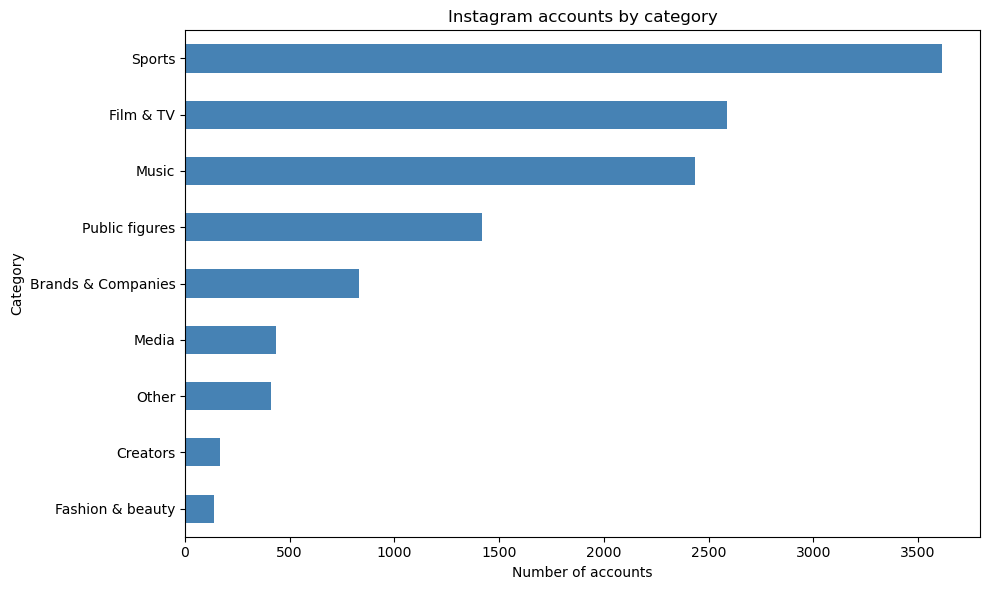

In [19]:
category_counts = exploded_data["category"].value_counts()
category_counts.sort_values().plot.barh(figsize=(10, 6), color="steelblue")
plt.title("Instagram accounts by category")
plt.xlabel("Number of accounts")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Sports has the most accounts in the dataset, followed by Film & TV and Music. Fashion & beauty and Creators have the fewest accounts.

This chart uses `exploded_data` so an account is counted in each category it belongs to. Category counts overlap, so their sum may be greater than the total number of accounts.

### 10. What are the two or three most important relationships in the data, shown and interpreted?

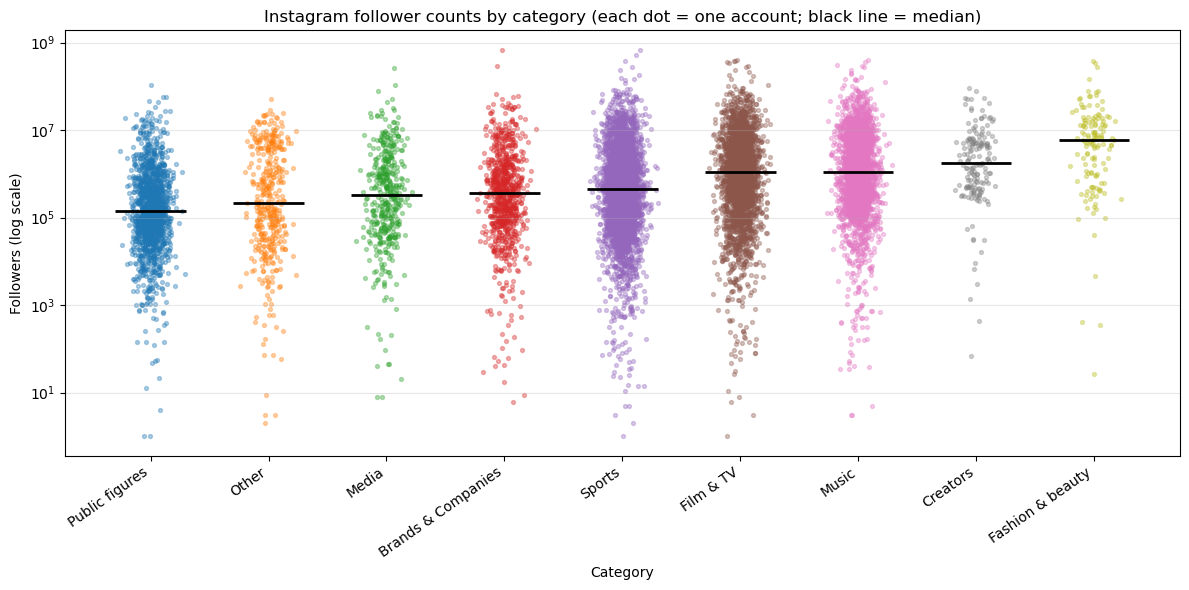

In [20]:
# Compare follower-count distributions across category memberships
rng = np.random.default_rng(631)

category_medians = exploded_data.groupby("category")["followers"].median().sort_values()
category_order = category_medians.index.tolist()
followers_by_category = [
    exploded_data.loc[exploded_data["category"] == category, "followers"]
    for category in category_order
]

fig, ax = plt.subplots(figsize=(12, 6))
for i, (category, values) in enumerate(zip(category_order, followers_by_category), start=1):
    x = rng.normal(loc=i, scale=0.08, size=len(values))
    ax.scatter(x, values, s=8, alpha=0.35)
    ax.hlines(values.median(), i - 0.3, i + 0.3, color="black", linewidth=2)

ax.set_xticks(range(1, len(category_order) + 1))
ax.set_xticklabels(category_order, rotation=35, ha="right")
ax.set_yscale("log")
ax.set_title("Instagram follower counts by category (each dot = one account; black line = median)")
ax.set_xlabel("Category")
ax.set_ylabel("Followers (log scale)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

This chart shows Instagram follower counts by category, with each dot as one account and the black line as the median. The y-axis is on a log scale, so each step up is ten times more followers.

Creative categories like Film & TV, Music, Creators, and Fashion & beauty tend to have higher median follower counts than other categories. Sports, Film & TV, and Music have the densest clusters with a wide range from thousands to tens of millions of followers. 

Fashion & beauty has the highest median, roughly 6 to 7 million followers, but it has the sparsest cluster of points. Public figures have the lowest median, around 10^5 followers.

The follower counts range over several orders of magnitude within each category, so the category alone doesn't fully predict follower count. However, we can see that some categories like Fashion & beauty tend to have a higher range of followers, so it would be interesting to perform further tests and analysis to confirm how strong this effect is or if it is just due to chance.

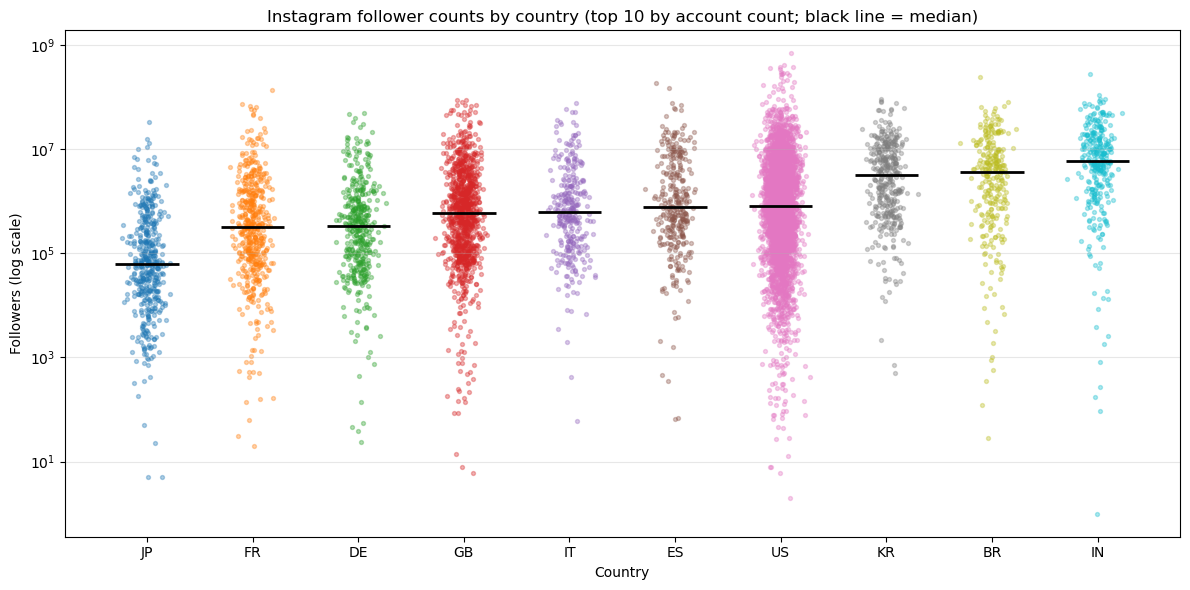

In [21]:
# graph follower counts by country
# Followers by country (top 10 countries by number of accounts)
country_data = data.dropna(subset=["country"])
top_countries = country_data["country"].value_counts().head(10).index.tolist()
country_data = country_data[country_data["country"].isin(top_countries)]

country_medians = (
    country_data.groupby("country")["followers"].median().sort_values()
)
country_order = country_medians.index.tolist()
followers_by_country = [
    country_data.loc[country_data["country"] == c, "followers"] for c in country_order
]

fig, ax = plt.subplots(figsize=(12, 6))
for i, values in enumerate(followers_by_country, start=1):
    x = rng.normal(loc=i, scale=0.08, size=len(values))
    ax.scatter(x, values, s=8, alpha=0.35)
    ax.hlines(values.median(), i - 0.3, i + 0.3, color="black", linewidth=2)

ax.set_xticks(range(1, len(country_order) + 1))
ax.set_xticklabels(country_order)
ax.set_yscale("log")
ax.set_title("Instagram follower counts by country (top 10 by account count; black line = median)")
ax.set_xlabel("Country")
ax.set_ylabel("Followers (log scale)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The graph above shows follower counts by top 10 countries with the most accounts, with each dot representing an account and the black line as the median. The y-axis is on a log scale, so each step up is ten times more followers.

The United States (US) has the most dense cluster of accounts. India (IN) has the highest median followers but with fewer accounts than the US, followed by Brazil (BR) and South Korea (KR).

Each country has a wide range of follower counts, so the country alone is not a strong indicator of follower count. Note that the US has the widest spread, with some accounts having the highest follower counts overall.

### 11. What's surprising here — what didn't the author expect to find?
Fashion & beauty has the highest median followers but fewer accounts than Sports, Film & TV, or Music. This is surprising because its typical account is larger than those in the other popular categories, even though its largest accounts don't match the top of the scale. 

Fashion and beauty may not have the most accounts, but the ones it has are quite popular and get a lot of attention. 

## Readiness

### 12. If I wanted to run an analysis tomorrow, what would I still have to do to this data?
This notebook doesn't handle missing country values because we're interested in the followers by categories. If you want to analyze by country, missing values would need to be addressed. It may be worth verifying if the accounts with missing country are global accounts with no specific ties to any country or actually missing country information.

You may need to decide how to handle the `also_in` column as it shows other categories an account belongs to. Only 37 accounts have this filled, so it might not matter much, but they're also top ranked accounts with millions of followers. This notebook splits accounts that belong to multiple categories into separate rows in the `exploded_data` table, but you may choose to handle them differently.

### 13. What analyses is this dataset ready to support?
The dataset is ready for analyzing and comparing follower counts by category. It can also support multi-category account analysis using the `exploded_data` table. You could also look at followers distribution using the `followers` or `log_followers` columns.

## My Own Questions
My question is whether a combination of category and country affects the follower count. Maybe some categories are more popular in certain countries? 

In this dataset, country is the country origin of the account holder, not where their audiences are. If we want to analyze account popularity by country, how should country be interpreted? Someone like Cristiano Ronaldo would be counted under Portugal (PT), but his reach is pretty much global. Does social media reward accounts equally regardless of country of origin, or if being from a certain country would give an advantage?